# Mini-tutorial: hoe een CART-beslisboom splitst met Gini-impurity en hoe pruning hem eenvoudiger maakt

**Mathematical Foundations – mini-tutorial** · Kemal Yilmaz · AP Hogeschool, IT & AI

## 1. Inleiding

Een **beslisboom voor classificatie** verdeelt de data stap voor stap met eenvoudige ja/nee-vragen, zoals "is de klant korter dan 12 maanden klant?". Elke vraag is een **split**. Elk eindpunt is een **blad** dat een klasse voorspelt.

Deze tutorial behandelt de twee wiskundige kernvragen van het **CART**-algoritme (*Classification And Regression Trees*, Breiman et al., 1984). CART is ook het algoritme achter scikit-learns `DecisionTreeClassifier`.

1. **Welke split kiest de boom?** Hij kiest de split die de **Gini-impurity** het sterkst laat dalen.
2. **Hoe voorkom je dat de boom te groot wordt?** Door de groei vooraf te begrenzen (`max_depth`) of door achteraf te snoeien met **cost-complexity pruning** (`ccp_alpha`).

**Link met mijn ML Principles-use-case.** Daar voorspelt een gesnoeide `DecisionTreeClassifier` klantverloop (*churn*) bij een telecombedrijf. De Kaggle-auteur kiest `ccp_alpha` met cross-validatie. Hij geeft geen splitsingscriterium op, dus vermoedelijk gebruikt de boom de standaardwaarde van scikit-learn: Gini. Deze tutorial legt de wiskunde achter beide stappen uit op een klein voorbeeld dat je met de hand kan narekenen.

## 2. Wiskundige uiteenzetting

### 2.1 Gini-impurity van een knoop

Neem een knoop $t$ met $n_t$ trainingsvoorbeelden, verdeeld over $K$ klassen. Stel $n_{t,k}$ is het aantal voorbeelden van klasse $k$ in de knoop. De **klassenverhouding** is dan

$$
p_k = \frac{n_{t,k}}{n_t}, \qquad \sum_{k=1}^{K} p_k = 1 .
$$

$p_k$ is het aandeel van klasse $k$ in de knoop. Bij churn is $p_1$ het aandeel vertrekkers en $p_0$ het aandeel blijvers. De **Gini-impurity** van de knoop is

$$
G(t) = 1 - \sum_{k=1}^{K} p_k^2 = \sum_{k=1}^{K} p_k\,(1 - p_k).
$$

**Interpretatie.** Trek willekeurig een voorbeeld uit de knoop en geef het een label dat je willekeurig trekt volgens de verhoudingen $p_k$. $G(t)$ is de kans dat dat label fout is. Een knoop is dus "onzuiver" als hij klassen door elkaar bevat.

Voor **twee klassen** met $p = p_1$ en $p_0 = 1 - p$ wordt dat

$$
G = 1 - p^2 - (1-p)^2 = 2\,p\,(1-p).
$$

- **Zuivere knoop** (alle voorbeelden in één klasse, $p = 0$ of $p = 1$): $G = 2 \cdot 1 \cdot 0 = 0$. Er valt niets meer te verbeteren.
- **Gelijk verdeelde binaire knoop** ($p = \tfrac12$): $G = 2 \cdot \tfrac12 \cdot \tfrac12 = 0{,}5$. Dat is het **maximum** voor twee klassen: de knoop zegt niets over de klasse.

### 2.2 De beste split: maximale daling van de impurity

Een split $s$, bijvoorbeeld $\text{tenure} \le 12$, verdeelt knoop $t$ in een linkerkind $t_L$ ($n_L$ voorbeelden) en een rechterkind $t_R$ ($n_R$ voorbeelden). De impurity *na* de split is het **gewogen gemiddelde** van beide kinderen:

$$
G_{\text{split}}(s) = \frac{n_L}{n_t}\,G(t_L) + \frac{n_R}{n_t}\,G(t_R).
$$

De weging zorgt ervoor dat een groot kind zwaarder doorweegt dan een klein kind. De **afname van de impurity** tegenover de ouderknoop is

$$
\Delta G(s) = G(t) - G_{\text{split}}(s).
$$

CART probeert **alle features** en voor een numerieke feature **alle drempels**. Dat zijn de middens tussen opeenvolgende, gesorteerde waarden. Het kiest de split met de grootste $\Delta G$:

$$
s^{*} = \arg\max_{s}\; \Delta G(s).
$$

Daarna herhaalt CART dit in elk kind afzonderlijk. Dat is **greedy**: elke stap is lokaal optimaal, maar het geheel is niet gegarandeerd de best mogelijke boom.

> Scikit-learn kan ook entropie als criterium gebruiken (`criterion="entropy"`, cf. informatietheorie in de cursus). Gini is de standaardinstelling en vergt geen logaritme.

### 2.3 Hoe voorspelt een blad?

Een nieuw voorbeeld volgt de splits tot in een blad $t$. Het blad voorspelt de **meest voorkomende klasse** onder de trainingsvoorbeelden in dat blad:

$$
\hat{y} = \arg\max_k\; p_k(t).
$$

De verhoudingen $p_k(t)$ zelf zijn de geschatte kansen die `predict_proba` teruggeeft. Bij twee klassen komt $\arg\max$ neer op "voorspel churn als $p_1(t) > 0{,}5$". Bij een gelijke stand kiest scikit-learn de eerste klasse, hier 0.

### 2.4 Overfitting en pruning

Zonder rem blijft CART splitsen. Een tak stopt pas wanneer de knoop zuiver is ($G = 0$) of wanneer er geen geldige splitsing meer mogelijk is, bijvoorbeeld bij voorbeelden met identieke features maar een ander label. In dat laatste geval blijft het blad onzuiver. Zo'n **zeer diepe boom** heeft vaak bladeren met maar één of enkele voorbeelden. Hij dreigt dan uitzonderingen en ruis "van buiten" te leren: op de trainingsdata scoort hij (bijna) perfect, maar op nieuwe data generaliseert hij vaak slechter. Dat risico heet **overfitting**. Twee manieren om dat te beperken:

**(a) Groei vooraf beperken** (*pre-pruning*), bijvoorbeeld met `max_depth`, `min_samples_leaf` of `min_impurity_decrease`. De boom stopt met groeien zodra hij de grens raakt, ongeacht wat er dieper nog te winnen viel. `max_depth=2` knipt *elke* tak op diepte 2 af, nuttig of niet.

**(b) Achteraf snoeien met cost-complexity pruning** (*post-pruning*). Laat de boom eerst volledig groeien. Weeg daarna voor elke deelboom $T$ af hoeveel impurity hij wegwerkt tegenover hoeveel bladeren hij daarvoor nodig heeft:

$$
R_\alpha(T) = R(T) + \alpha\,\lvert \tilde T \rvert ,
\qquad
R(T) = \sum_{t \in \tilde T} \frac{n_t}{n}\, G(t).
$$

- $\tilde T$ is de verzameling bladeren en $\lvert \tilde T \rvert$ het aantal bladeren: de *complexiteit*.
- $R(T)$ is de **trainingsimpurity**: de Gini van elk blad, gewogen met het aandeel trainingsvoorbeelden $n_t/n$ in dat blad. Scikit-learn gebruikt hiervoor de impurity. Breiman et al. gebruikten oorspronkelijk de foutclassificatieratio, maar het principe is hetzelfde.
- $\alpha \ge 0$ (`ccp_alpha`) is de **prijs per blad**.

Voor elke $\alpha$ kies je de deelboom van de volledige boom met de kleinste $R_\alpha(T)$.

- $\alpha = 0$: bladeren zijn gratis, dus de volledige boom wint, want die heeft de laagste trainingsimpurity $R(T)$. Dat is alleen $R(T) = 0$ als alle bladeren zuiver zijn, zoals in ons voorbeeld (§3.6). In het algemeen kan een volledig uitgegroeide boom nog onzuivere bladeren hebben.
- **Hogere $\alpha$**: elk extra blad kost meer. Een split blijft alleen staan als hij de trainingsimpurity *meer* laat dalen dan hij aan bladkost toevoegt. De optimale boom wordt kleiner, en de trainingsimpurity stijgt daarbij.
- Zeer grote $\alpha$: alleen de wortel blijft over (één blad).

Wanneer valt een tak weg? Voor een interne knoop $t$ met deelboom $T_t$ vergelijk je de knoop als blad (impurity $R(t) = \tfrac{n_t}{n} G(t)$) met de hele deelboom eronder. Beide zijn even goed bij de **effectieve $\alpha$**:

$$
g(t) = \frac{R(t) - R(T_t)}{\lvert \tilde T_t \rvert - 1}.
$$

In woorden: hoeveel impurity de tak wegwerkt *per extra blad*. Het **weakest-link**-algoritme snoeit telkens de tak met de kleinste $g(t)$. Zo ontstaat een reeks geneste bomen $T_0 \supset T_1 \supset \dots \supset \{\text{wortel}\}$ met bijhorende drempels voor $\alpha$. Dit is precies wat `cost_complexity_pruning_path` berekent. Welke $\alpha$ het best generaliseert, volgt niet uit de formule zelf. Die kies je met **validatie**, bijvoorbeeld cross-validatie.

## 3. Uitgewerkt voorbeeld

### 3.1 De dataset

> ⚠️ **Didactische dataset.** De 12 klanten hieronder zijn **zelf verzonnen** om de berekeningen met de hand te kunnen volgen. Het is *geen* steekproef uit de echte Telco-dataset. De opbouw volgt wel het patroon uit die dataset: nieuwe klanten vertrekken vaker.

We gebruiken één feature: `tenure`, het aantal maanden dat iemand klant is. De target is `churn` (1 = vertrokken, 0 = gebleven). Er zitten twee bewuste **uitzonderingen** in: klant C04 is pas 5 maanden klant maar bleef, en klant C11 is al 41 maanden klant maar vertrok.

De data wordt in het notebook zelf aangemaakt, dus er is niets op te halen. Alle gebruikte packages zitten in de cursusomgeving.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

klanten = pd.DataFrame(
    {
        "tenure": [1, 2, 3, 5, 8, 11, 14, 20, 26, 33, 41, 50],
        "churn": [1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0],
    },
    index=[f"C{i:02d}" for i in range(1, 13)],
)
X = klanten[["tenure"]]
y = klanten["churn"].to_numpy()
klanten.T

,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,C11,C12
tenure,1,2,3,5,8,11,14,20,26,33,41,50
churn,1,1,1,0,1,1,0,0,0,0,1,0


### 3.2 Gini van de ouderknoop (de wortel)

De wortel bevat alle 12 klanten: 6 vertrekkers en 6 blijvers, dus $p_1 = p_0 = \tfrac{6}{12} = \tfrac12$.

$$
G(\text{wortel}) = 1 - \left(\tfrac12\right)^2 - \left(\tfrac12\right)^2 = 1 - \tfrac14 - \tfrac14 = 0{,}5
$$

Dit is precies de **gelijk verdeelde binaire knoop** uit §2.1: de maximale impurity voor twee klassen.

### 3.3 Twee kandidaat-splitsingen met de hand

We vergelijken twee bedrijfsmatig voor de hand liggende drempels: **een half jaar** ($\text{tenure} \le 6$) en **een jaar** ($\text{tenure} \le 12$).

**Split A: $\text{tenure} \le 6$**

| knoop | klanten | churn (1) | blijft (0) | n |
|---|---|---|---|---|
| links: tenure ≤ 6 | C01–C04 | 3 | 1 | 4 |
| rechts: tenure > 6 | C05–C12 | 3 | 5 | 8 |

$$
G(t_L) = 1 - \left(\tfrac34\right)^2 - \left(\tfrac14\right)^2 = \tfrac{6}{16} = 0{,}375
\qquad
G(t_R) = 1 - \left(\tfrac38\right)^2 - \left(\tfrac58\right)^2 = \tfrac{30}{64} = 0{,}46875
$$

$$
G_{\text{split}}(A) = \tfrac{4}{12}\cdot 0{,}375 + \tfrac{8}{12}\cdot 0{,}46875 = 0{,}125 + 0{,}3125 = 0{,}4375
\qquad
\Delta G(A) = 0{,}5 - 0{,}4375 = 0{,}0625
$$

**Split B: $\text{tenure} \le 12$**

| knoop | klanten | churn (1) | blijft (0) | n |
|---|---|---|---|---|
| links: tenure ≤ 12 | C01–C06 | 5 | 1 | 6 |
| rechts: tenure > 12 | C07–C12 | 1 | 5 | 6 |

$$
G(t_L) = 1 - \left(\tfrac56\right)^2 - \left(\tfrac16\right)^2 = \tfrac{10}{36} \approx 0{,}2778
\qquad
G(t_R) = 1 - \left(\tfrac16\right)^2 - \left(\tfrac56\right)^2 = \tfrac{10}{36} \approx 0{,}2778
$$

$$
G_{\text{split}}(B) = \tfrac{6}{12}\cdot \tfrac{10}{36} + \tfrac{6}{12}\cdot \tfrac{10}{36} = \tfrac{10}{36} \approx 0{,}2778
\qquad
\Delta G(B) = 0{,}5 - 0{,}2778 \approx 0{,}2222
$$

**Conclusie.** Split B haalt de impurity bijna vier keer zo sterk omlaag als split A (0,2222 tegenover 0,0625). CART verkiest dus **B**. Split A maakt de linkerknoop wel vrij zuiver, maar laat een grote, sterk gemengde rechterknoop over (3 tegen 5). Door de weging $\tfrac{8}{12}$ telt die zwaar door. Split B maakt *beide* kinderen even zuiver.

### 3.4 Controle in Python

Hieronder staan de formules uit §2 letterlijk in code. Ze rekenen de twee kandidaten na en daarna *alle* 11 mogelijke drempels, zoals CART zelf doet.

In [2]:
def gini(labels):
    # G = 1 - som_k p_k^2
    _, aantallen = np.unique(labels, return_counts=True)
    p = aantallen / aantallen.sum()
    return 1 - np.sum(p**2)


def evalueer_split(x, labels, drempel):
    links, rechts = labels[x <= drempel], labels[x > drempel]
    n_l, n_r, n = len(links), len(rechts), len(labels)
    g_split = n_l / n * gini(links) + n_r / n * gini(rechts)
    return {
        "drempel": drempel,
        "links churn/blijft": f"{links.sum()}/{n_l - links.sum()}",
        "G links": gini(links),
        "rechts churn/blijft": f"{rechts.sum()}/{n_r - rechts.sum()}",
        "G rechts": gini(rechts),
        "G split (gewogen)": g_split,
        "afname ΔG": gini(labels) - g_split,
    }


x = klanten["tenure"].to_numpy()
print("Controle 2.1: zuiver =", gini(np.array([1, 1, 1])), "| 50/50 =", gini(np.array([0, 1])))
print("G(wortel) =", gini(y))

kandidaten = pd.DataFrame([evalueer_split(x, y, 6), evalueer_split(x, y, 12)], index=["A", "B"])
assert np.isclose(kandidaten.loc["A", "G split (gewogen)"], 0.4375)
assert np.isclose(kandidaten.loc["B", "G split (gewogen)"], 10 / 36)
kandidaten.round(4)

Controle 2.1: zuiver = 0.0 | 50/50 = 0.5
G(wortel) = 0.5


,drempel,links churn/blijft,G links,rechts churn/blijft,G rechts,G split (gewogen),afname ΔG
A,6,3/1,0.3750,3/5,0.4688,0.4375,0.0625
B,12,5/1,0.2778,1/5,0.2778,0.2778,0.2222


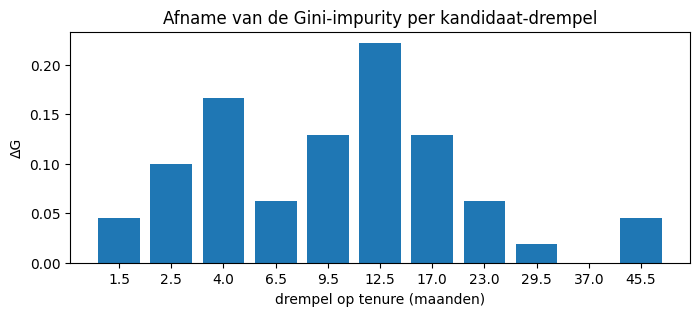

Beste drempel: tenure <= 12.5  (ΔG = 0.2222)
scikit-learn wortelsplit: tenure <= 12.5
Gini wortel / links / rechts: [0.5    0.2778 0.2778]


In [3]:
# Alle drempels die CART overweegt: middens tussen opeenvolgende gesorteerde waarden
waarden = np.sort(np.unique(x))
middens = (waarden[:-1] + waarden[1:]) / 2
alle_splits = pd.DataFrame([evalueer_split(x, y, d) for d in middens])

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(alle_splits["drempel"].astype(str), alle_splits["afname ΔG"], color="tab:blue")
ax.set(xlabel="drempel op tenure (maanden)", ylabel="ΔG", title="Afname van de Gini-impurity per kandidaat-drempel")
plt.show()

beste = alle_splits.loc[alle_splits["afname ΔG"].idxmax()]
print(f"Beste drempel: tenure <= {beste['drempel']}  (ΔG = {beste['afname ΔG']:.4f})")

# Kiest scikit-learn dezelfde eerste split?
stomp = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y)
print("scikit-learn wortelsplit: tenure <=", stomp.tree_.threshold[0])
print("Gini wortel / links / rechts:", stomp.tree_.impurity.round(4))

De drempel 12,5 ligt tussen 11 en 14 maanden en geeft dezelfde verdeling als "$\le 12$". Split B is dus niet alleen de beste van onze twee kandidaten, maar ook de **beste van alle drempels**. Scikit-learn kiest dezelfde wortelsplit, met dezelfde Gini-waarden (0,5 / 0,2778 / 0,2778).

### 3.5 Voorspellen in een blad

Na split B hebben we twee bladeren:

- **links** ($\text{tenure} \le 12$): 5 vertrekkers en 1 blijver, dus $p_1 = \tfrac56 \approx 0{,}83$. Voorspelling: **churn**.
- **rechts** ($\text{tenure} > 12$): 1 vertrekker en 5 blijvers, dus $p_1 = \tfrac16 \approx 0{,}17$. Voorspelling: **blijft**.

Een nieuwe klant van 4 maanden komt links terecht, een nieuwe klant van 30 maanden rechts:

In [4]:
nieuw = pd.DataFrame({"tenure": [4, 30]})
pd.DataFrame(
    {
        "tenure": nieuw["tenure"],
        "P(blijft)": stomp.predict_proba(nieuw)[:, 0].round(3),
        "P(churn)": stomp.predict_proba(nieuw)[:, 1].round(3),
        "voorspelling": stomp.predict(nieuw),
    }
)

,tenure,P(blijft),P(churn),voorspelling
0,4,0.167,0.833,1
1,30,0.833,0.167,0


### 3.6 Een volledig uitgegroeide boom: risico op overfitting

In ons voorbeeld hebben alle klanten een verschillende `tenure`. Zonder beperkingen kan CART dus doorgaan tot elk blad zuiver is. Kijk vooral naar wat er met de twee uitzonderingen C04 en C11 gebeurt.

In [5]:
volledige_boom = DecisionTreeClassifier(random_state=0).fit(X, y)
print(export_text(volledige_boom, feature_names=["tenure"]))
print("Aantal bladeren:", volledige_boom.get_n_leaves(), "| diepte:", volledige_boom.get_depth())
print("Accuracy op de trainingsdata:", volledige_boom.score(X, y))

|--- tenure <= 12.50
|   |--- tenure <= 4.00
|   |   |--- class: 1
|   |--- tenure >  4.00
|   |   |--- tenure <= 6.50
|   |   |   |--- class: 0
|   |   |--- tenure >  6.50
|   |   |   |--- class: 1
|--- tenure >  12.50
|   |--- tenure <= 37.00
|   |   |--- class: 0
|   |--- tenure >  37.00
|   |   |--- tenure <= 45.50
|   |   |   |--- class: 1
|   |   |--- tenure >  45.50
|   |   |   |--- class: 0

Aantal bladeren: 6 | diepte: 3
Accuracy op de trainingsdata: 1.0


De volledige boom heeft **6 bladeren**, die allemaal zuiver zijn ($R(T) = 0$), en classificeert alle trainingsklanten correct. Maar kijk naar de regels die hij daarvoor maakt:

- "klanten tussen 4 en 6,5 maanden blijven": die regel steunt op **één klant** (C04);
- "klanten tussen 37 en 45,5 maanden vertrekken": die regel steunt op **één klant** (C11).

Dat lijken eerder uitzonderingen dan patronen. Een nieuwe klant van 5 maanden krijgt "blijft" voorspeld, terwijl 5 van de 6 klanten onder een jaar vertrokken. De 100 % trainingsaccuracy en de twee bladeren met elk één klant **illustreren het risico op overfitting**: een complexer model past de trainingsdata beter, maar dat zegt op zich niets over nieuwe klanten. Of deze volledige boom echt slechter generaliseert dan een gesnoeide boom, kan je met deze 12 klanten niet aantonen. Daarvoor heb je evaluatie op nieuwe data nodig (validatie of test).

### 3.7 Cost-complexity pruning met de hand

We berekenen $g(t)$ uit §2.4 voor de interne knopen. We hebben $n = 12$, en een zuiver blad heeft $G = 0$.

**Rechtertak** (knoop "$\text{tenure} > 12$", 6 klanten, 1 churn): als blad is $R(t) = \tfrac{6}{12}\cdot\tfrac{10}{36} = \tfrac{5}{36}$. De deelboom eronder heeft 3 zuivere bladeren, dus $R(T_t) = 0$ en

$$
g = \frac{\tfrac{5}{36} - 0}{3 - 1} = \frac{5}{72} \approx 0{,}0694 .
$$

**Linkertak** (knoop "$\text{tenure} \le 12$"): de situatie is symmetrisch (5 tegen 1, 3 bladeren), dus ook $g = \tfrac{5}{72} \approx 0{,}0694$.

**Dieper gelegen knopen** hebben een grotere $g$. Neem de knoop "$\text{tenure} > 37$" met C11 en C12: $R(t) = \tfrac{2}{12}\cdot 0{,}5 = \tfrac{1}{12}$ en 2 bladeren, dus $g = \tfrac{1}{12} \approx 0{,}0833$. De knoop "$4 < \text{tenure} \le 12$" geeft op dezelfde manier $g = \tfrac{3}{12}\cdot\tfrac49 = \tfrac19 \approx 0{,}111$. De zwakste schakels zijn dus de twee hele takken onder de wortel, en die vallen allebei weg bij $\alpha = \tfrac{5}{72}$. Wat overblijft is de stomp van split B.

**Wortel** (na het snoeien van beide takken): $R(\text{wortel}) = 0{,}5$ en de stomp heeft $R = \tfrac{10}{36}$ met 2 bladeren, dus

$$
g = \frac{0{,}5 - \tfrac{10}{36}}{2 - 1} = \frac{2}{9} \approx 0{,}2222 .
$$

Dat is precies de afname $\Delta G(B)$ uit §3.3. Bij de laatste split meet $g$ gewoon hoeveel impurity die ene split wegwerkt.

Zo krijgen we drie kandidaat-bomen met hun kostfunctie $R_\alpha(T) = R(T) + \alpha \lvert \tilde T \rvert$:

| boom | bladeren | trainingsimpurity $R(T)$ | $R_\alpha(T)$ | optimaal voor |
|---|---|---|---|---|
| $T_0$: volledige boom | 6 | $0$ | $6\alpha$ | $0 \le \alpha < \tfrac{5}{72}$ |
| $T_1$: stomp (split B) | 2 | $\tfrac{10}{36} \approx 0{,}278$ | $0{,}278 + 2\alpha$ | $\tfrac{5}{72} \le \alpha < \tfrac29$ |
| $T_2$: enkel de wortel | 1 | $0{,}5$ | $0{,}5 + \alpha$ | $\alpha \ge \tfrac29$ |

Hoe hoger $\alpha$, hoe meer **trainingsimpurity** we accepteren in ruil voor **minder bladeren**: van 6 bladeren met impurity 0, over 2 bladeren met impurity 0,278, naar 1 blad met impurity 0,5. Scikit-learn berekent hetzelfde pad:

,ccp_alpha,R(T) trainingsimpurity,bladeren na deze snoeistap
0,0.0000,0.0000,6
1,0.0694,0.1389,4
2,0.0694,0.2778,2
3,0.2222,0.5000,1


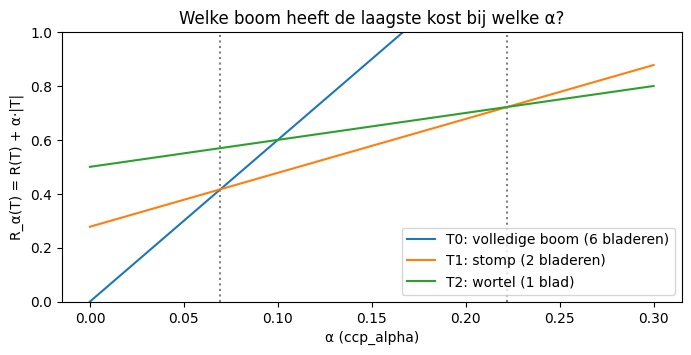

In [6]:
pad = volledige_boom.cost_complexity_pruning_path(X, y)
pad_tabel = pd.DataFrame({"ccp_alpha": pad.ccp_alphas, "R(T) trainingsimpurity": pad.impurities})
pad_tabel["bladeren na deze snoeistap"] = [6, 4, 2, 1]
assert np.allclose(np.unique(pad.ccp_alphas.round(10)), [0, 5 / 72, 2 / 9])
display(pad_tabel.round(4))

# R_alpha(T) van de drie bomen als functie van alpha
alphas = np.linspace(0, 0.3, 301)
fig, ax = plt.subplots(figsize=(8, 3.5))
for naam, r_t, bladeren in [("T0: volledige boom (6 bladeren)", 0, 6),
                            ("T1: stomp (2 bladeren)", 10 / 36, 2),
                            ("T2: wortel (1 blad)", 0.5, 1)]:  # fmt: skip
    ax.plot(alphas, r_t + alphas * bladeren, label=naam)
for a in (5 / 72, 2 / 9):
    ax.axvline(a, color="grey", ls=":")
ax.set(xlabel="α (ccp_alpha)", ylabel="R_α(T) = R(T) + α·|T|",
       title="Welke boom heeft de laagste kost bij welke α?", ylim=(0, 1))  # fmt: skip
ax.legend()
plt.show()

Op de grafiek ligt de laagste lijn bij elke $\alpha$ bij de boom die cost-complexity pruning kiest. De snijpunten liggen precies bij $\tfrac{5}{72} \approx 0{,}069$ en $\tfrac29 \approx 0{,}222$.

Het pad van scikit-learn bevat $\tfrac{5}{72}$ twee keer. Het weakest-link-algoritme snoeit één tak per stap. De tussenrij met $R(T) = \tfrac{5}{36} \approx 0{,}139$ is de boom waarin pas één van de twee takken gesnoeid is (4 bladeren). Omdat beide takken dezelfde $g$ hebben, valt de tweede bij dezelfde $\alpha$ weg. Wie `ccp_alpha` $= \tfrac{5}{72}$ instelt, krijgt dus meteen de stomp met 2 bladeren.

Hieronder staan de volledige boom en de gesnoeide boom voor een $\alpha$ tussen de twee drempels ($\alpha = 0{,}1$).

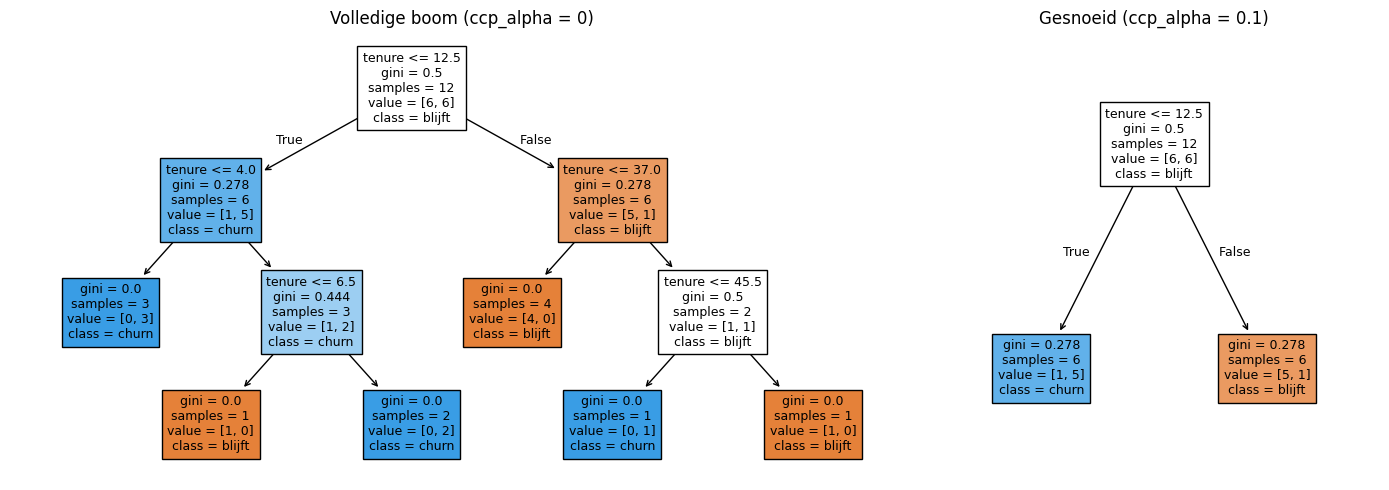

In [7]:
gesnoeide_boom = DecisionTreeClassifier(random_state=0, ccp_alpha=0.1).fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
for ax, boom, titel in [(axes[0], volledige_boom, "Volledige boom (ccp_alpha = 0)"),
                        (axes[1], gesnoeide_boom, "Gesnoeid (ccp_alpha = 0.1)")]:  # fmt: skip
    plot_tree(boom, feature_names=["tenure"], class_names=["blijft", "churn"],
              filled=True, impurity=True, ax=ax, fontsize=9)  # fmt: skip
    ax.set_title(titel)
plt.tight_layout()
plt.show()

### 3.8 `max_depth` tegenover `ccp_alpha`

In [8]:
via_max_depth = DecisionTreeClassifier(random_state=0, max_depth=1).fit(X, y)
print("Vooraf beperkt met max_depth=1:")
print(export_text(via_max_depth, feature_names=["tenure"]))
print("Achteraf gesnoeid met ccp_alpha=0.1:")
print(export_text(gesnoeide_boom, feature_names=["tenure"]))

Vooraf beperkt met max_depth=1:
|--- tenure <= 12.50
|   |--- class: 1
|--- tenure >  12.50
|   |--- class: 0

Achteraf gesnoeid met ccp_alpha=0.1:
|--- tenure <= 12.50
|   |--- class: 1
|--- tenure >  12.50
|   |--- class: 0



In dit kleine voorbeeld komen `max_depth=1` en `ccp_alpha=0.1` toevallig op **dezelfde boom** uit. De weg ernaartoe is wel fundamenteel anders:

| | `max_depth` (vooraf beperken) | `ccp_alpha` (achteraf snoeien) |
|---|---|---|
| wanneer? | tijdens het groeien: stoppen bij een vaste diepte | na het groeien: eerst de volledige boom, dan takken weghalen |
| criterium | alleen de diepte, voor alle takken gelijk | per tak: impurity-winst per extra blad, $g(t)$ |
| gevolg | een nuttige diepe split gaat verloren, een nutteloze ondiepe split blijft | elke tak wordt op eigen merites beoordeeld; de boom kan aan de ene kant diep en aan de andere kant ondiep zijn |
| risico | één diepte voor de hele boom: te klein mist echte patronen dieper in de boom, te groot laat ruis staan | meer rekenwerk: eerst de volledige boom bouwen, en $\alpha$ moet nog gekozen worden |

Hier vallen ze samen omdat beide takken symmetrisch zijn en tegelijk wegvallen. Op echte data met tientallen features en duizenden klanten geven ze meestal verschillende bomen. Bij beide methoden geldt: de trainingsdata alleen bepalen niet hoe sterk je moet snoeien. Dat bepaal je met validatiedata.

## 4. Terug naar de churncase

In de Kaggle-notebook die mijn ML Principles-use-case documenteert (Borbekov, *Telco Churn Prediction – Tree Methods Compared*, onderdeel *Decision Tree*) zie je precies deze stappen:

- De boom is een `DecisionTreeClassifier` zonder opgegeven `criterion`. De auteur vermeldt het criterium nergens. Volgens de scikit-learn-documentatie is de standaardwaarde **Gini-impurity** (§2.1–2.2), dus vermoedelijk is dat het criterium. Dat is een afleiding, geen gegeven uit de bron.
- De auteur laat eerst een volledige boom groeien. Daarna berekent hij met `cost_complexity_pruning_path` alle effectieve $\alpha$'s (§2.4, §3.7), en kiest hij met 5-fold cross-validatie (`GridSearchCV`, scoring F1) de beste `ccp_alpha` ≈ 0,00073. Dat levert een boom met 34 bladeren op.
- De reden om te snoeien is dezelfde als in §3.6: een volledig uitgegroeide boom loopt het risico uitzonderingen van buiten te leren. De auteur rapporteert alleen het resultaat van de gesnoeide boom: een CV-F1 van 0,570 en een test-F1 van 0,562. Hoe de ongesnoeide boom scoorde, staat niet in de bron.

De gekozen waarde (≈ 0,00073) is niet rechtstreeks te vergelijken met de drempels $\tfrac{5}{72}$ en $\tfrac29$ uit ons voorbeeld. Ze hangt af van de boom en de data, en de auteur kiest ze met cross-validatie, niet met de hand.

## 5. Samenvatting

- **Gini-impurity** $G = 1 - \sum_k p_k^2$ meet hoe gemengd een knoop is: 0 bij een zuivere knoop, 0,5 bij een 50/50-knoop met twee klassen.
- CART kiest greedy de split met de grootste **afname van de gewogen Gini**. In het voorbeeld wint "tenure ≤ 12" (ΔG = 0,222) van "tenure ≤ 6" (ΔG = 0,0625).
- Een **blad** voorspelt de meerderheidsklasse; de klassenverhoudingen zijn de voorspelde kansen.
- Een **volledig uitgegroeide boom** splitst tot een knoop zuiver is of niet meer gesplitst kan worden, en loopt zo het risico uitzonderingen van buiten te leren (overfitting). `max_depth` beperkt de groei vooraf. **Cost-complexity pruning** zoekt achteraf de deelboom die $R(T) + \alpha \lvert \tilde T \rvert$ minimaliseert. Een hogere `ccp_alpha` ruilt trainingsimpurity in voor minder bladeren. De beste $\alpha$ kies je met validatie.

## Bronnen

- Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth – CART, Gini-criterium en cost-complexity pruning.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, hoofdstuk 8 (Tree-Based Methods). <https://www.statlearning.com/>
- scikit-learn-documentatie: *Decision Trees* (§ Mathematical formulation, § Minimal Cost-Complexity Pruning). <https://scikit-learn.org/stable/modules/tree.html>
- Diependaele, K. *ML Principles – Gestructureerde data / Decision trees* en *Mathematical Foundations* (cursusmateriaal AP Hogeschool). <https://ap-mdi-it.github.io/ml-courses/>
- Borbekov, B. (2026). *Telco Churn Prediction – Tree Methods Compared* [Kaggle-notebook], onderdeel *Decision Tree*. <https://www.kaggle.com/code/bekzhanborbekov/telco-churn-prediction-tree-methods-compared>
- Dataset in het uitgewerkte voorbeeld: zelf samengesteld (didactisch, niet afkomstig uit een bestaande bron).